# Import Library & Inisialisasi Environment

In [2]:
#202431132_Kayla N R Maskat
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load Dataset

In [11]:
#202431132_Kayla N R MAskat
df = pd.read_csv('04_bank_customers.csv', sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# Exploratory Data Analysis (EDA) & Cek Missing Value

In [14]:
#202431132_Kayla N R Maskat
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
None
age          0
job          0
marital      0
education    0
default      0
balance      0
hous

# Preprocessing Data - Encoding Variable Kategorikal

In [20]:
#202431132_Kayla N R Maskat
df_encoded = df.copy()
label_encoders = {}

#Mengambil semua kolom yang bertipe object (kategorikal)
categorical_cols = df_encoded.select_dtypes(include=['object']).columns

#Melakukan encoding untuk setiap kolom kategorikal
for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

df_encoded.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3,0


# Pemisahan Fitur & Target dan Pembagian Data Train-Test

In [22]:
#202431132_Kayla N R Maskat
#Memisahkan Fitur (X) dan Target (y)
X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

#Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Data Latih: {X_train.shape[0]} baris | Data Uji: {X_test.shape[0]} baris")

Data Latih: 36168 baris | Data Uji: 9043 baris


# Pemodelan & Evaluasi Algoritma 1: Decision Tree

In [27]:
#202431132_Kayla N R Maskat
#Inisialisasi dan pelatihan model Decision Tree
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

#Prediksi data uji
y_pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

print(f"Akurasi Decision Tree: {acc_dt * 100:.2f}%\n")
print("=== Classification Report Decision Tree ===")
print(classification_report(y_test, y_pred_dt, target_names=['No (0)', 'Yes (1)']))

Akurasi Decision Tree: 89.70%

=== Classification Report Decision Tree ===
              precision    recall  f1-score   support

      No (0)       0.92      0.96      0.94      7985
     Yes (1)       0.59      0.40      0.47      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.68      0.71      9043
weighted avg       0.88      0.90      0.89      9043



# Pemodelan & Evaluasi Algoritma 2: Naïve Bayes

In [30]:
#202431132_Kayla N R Maskat
#Inisialisasi dan pelatihan model Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

#Prediksi data uji
y_pred_nb = nb_model.predict(X_test)
acc_nb = accuracy_score(y_test, y_pred_nb)

print(f"Akurasi Naïve Bayes: {acc_nb * 100:.2f}%\n")
print("=== Classification Report Naïve Bayes ===")
print(classification_report(y_test, y_pred_nb, target_names=['No (0)', 'Yes (1)']))

Akurasi Naïve Bayes: 84.45%

=== Classification Report Naïve Bayes ===
              precision    recall  f1-score   support

      No (0)       0.92      0.90      0.91      7985
     Yes (1)       0.37      0.45      0.40      1058

    accuracy                           0.84      9043
   macro avg       0.65      0.67      0.66      9043
weighted avg       0.86      0.84      0.85      9043



# Visualisasi Confusion Matrix Kedua Algoritma

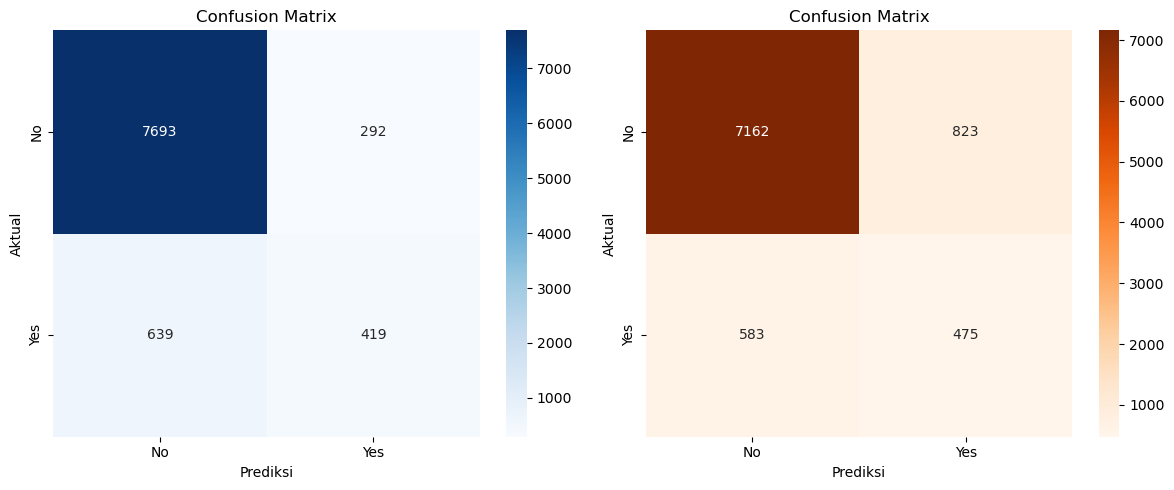

In [35]:
#202431132_Kayla N R Maskat
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#Confusion Matrix Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

#Confusion Matrix Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
axes[1].set_title('Confusion Matrix')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

# Grafik Bar Perbandingan Akurasi Algoritma

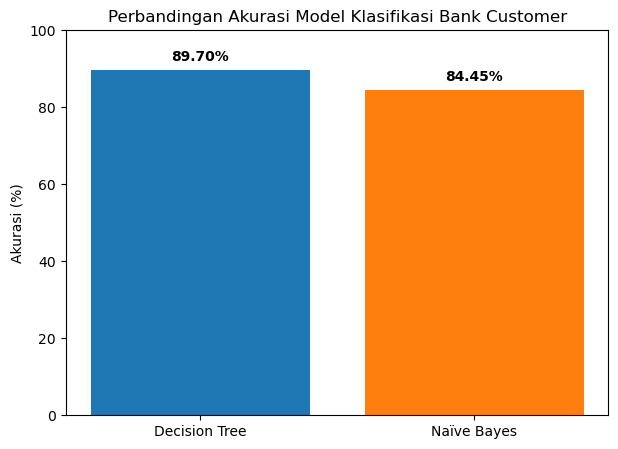

In [40]:
#202431132_Kayla N R Maskat
models = ['Decision Tree', 'Naïve Bayes']
accuracies = [acc_dt * 100, acc_nb * 100]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies, color=['#1f77b4', '#ff7f0e'])
plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.title('Perbandingan Akurasi Model Klasifikasi Bank Customer')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.show()

# Visualisasi Struktur Pohon Keuputusan (Decision Tree Plot)

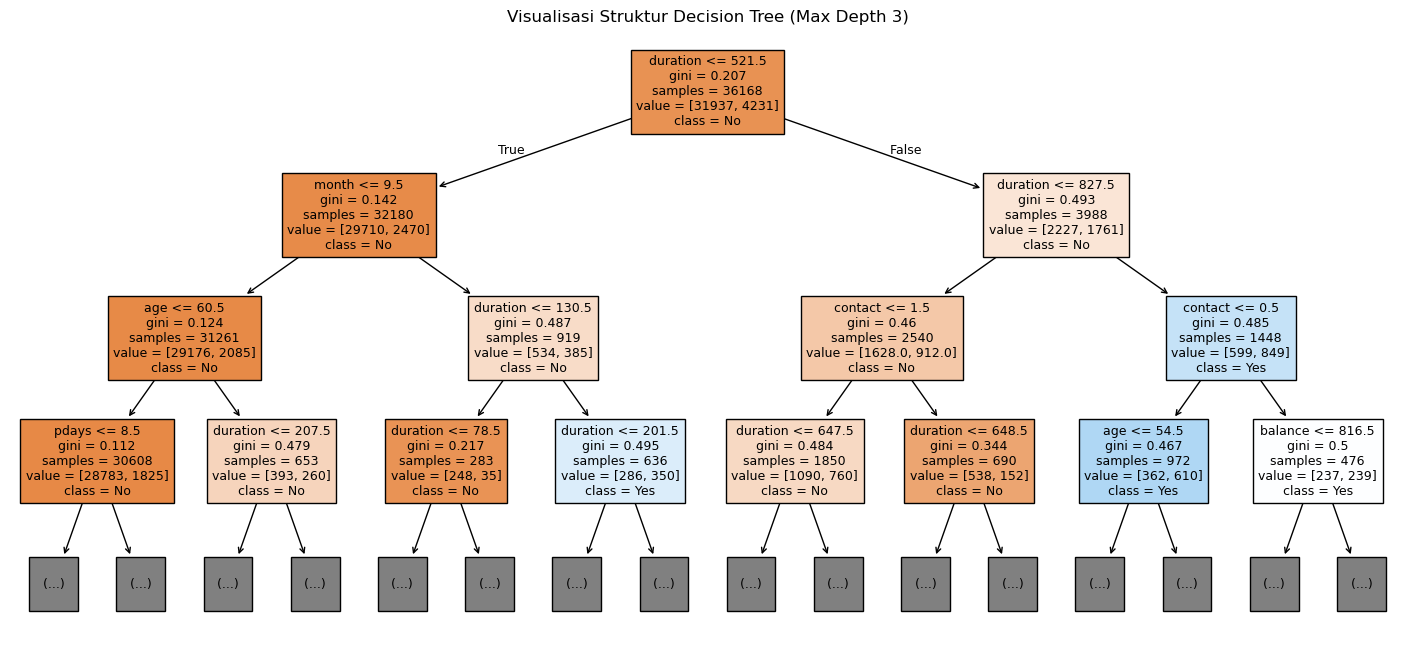

In [43]:
#202431132_Kayla N R Maskat
plt.figure(figsize=(18, 8))
plot_tree(dt_model, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, max_depth=3, fontsize=9)
plt.title('Visualisasi Struktur Decision Tree (Max Depth 3)')
plt.show()